# Notebook 05: Agent-Based Models

**Paper Reference:** Gould et al. (2013), Sections 5.1–5.3

This notebook compares three models of increasing sophistication:
1. **Smith et al. (2003)** — Zero intelligence (Poisson, uniform)
2. **Mike & Farmer (2008)** — Empirically calibrated (power-law prices, long-memory signs)
3. **Parlour (1998)** — Strategic placement (agents condition on book state)

We run each model and compare which stylized facts they reproduce.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.mike_farmer import MikeFarmerModel
from lob.models.strategic import ParlourModel
from lob.metrics import compute_log_returns
from lob.analysis.stylized_facts import (
    compute_acf, compute_hurst_rs, hill_estimator,
    compute_volatility_clustering
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf

set_style()

## 1. Run All Three Models

We run each model for 50,000 events (after 5,000 warmup) and collect comparable statistics.

In [2]:
models = {
    'ZI (Smith et al.)': SmithFarmerModel(
        mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000
    ),
    'Mike-Farmer': MikeFarmerModel(
        mu=1.0, lam=2.0, delta=0.05, alpha_price=1.5, hurst=0.7,
        initial_mid=10000, size_mean=0.5, size_sigma=0.3
    ),
    'Parlour (Strategic)': ParlourModel(
        arrival_rate=5.0, delta=0.05, spread_threshold=5,
        depth_threshold=10, initial_mid=10000
    ),
}

config = SimulationConfig(n_events=50_000, warmup_events=5_000, seed=42)

results = {}
for name, model in models.items():
    print(f"Running {name}...")
    reset_order_id_counter()
    sim = Simulation(model=model, config=config)
    df = sim.run(progress=True)
    
    valid = df.dropna(subset=['mid_price'])
    mid_prices = valid['mid_price'].values
    log_ret = compute_log_returns(mid_prices)
    log_ret = log_ret[np.isfinite(log_ret)]
    
    results[name] = {
        'df': df, 'valid': valid, 'mid_prices': mid_prices,
        'log_returns': log_ret, 'book': sim.book,
    }
    print(f"  {len(valid)} valid events, mean spread = {valid['spread'].mean():.2f}\n")

Running ZI (Smith et al.)...


Simulating: 100%|██████████| 55000/55000 [00:01<00:00, 48788.06it/s]


  50000 valid events, mean spread = 75.82

Running Mike-Farmer...


Simulating: 100%|██████████| 55000/55000 [00:00<00:00, 111741.21it/s]


  47258 valid events, mean spread = 3.02

Running Parlour (Strategic)...


Simulating: 100%|██████████| 55000/55000 [00:00<00:00, 79617.48it/s]


  50000 valid events, mean spread = 302.95



## 2. Price Series Comparison

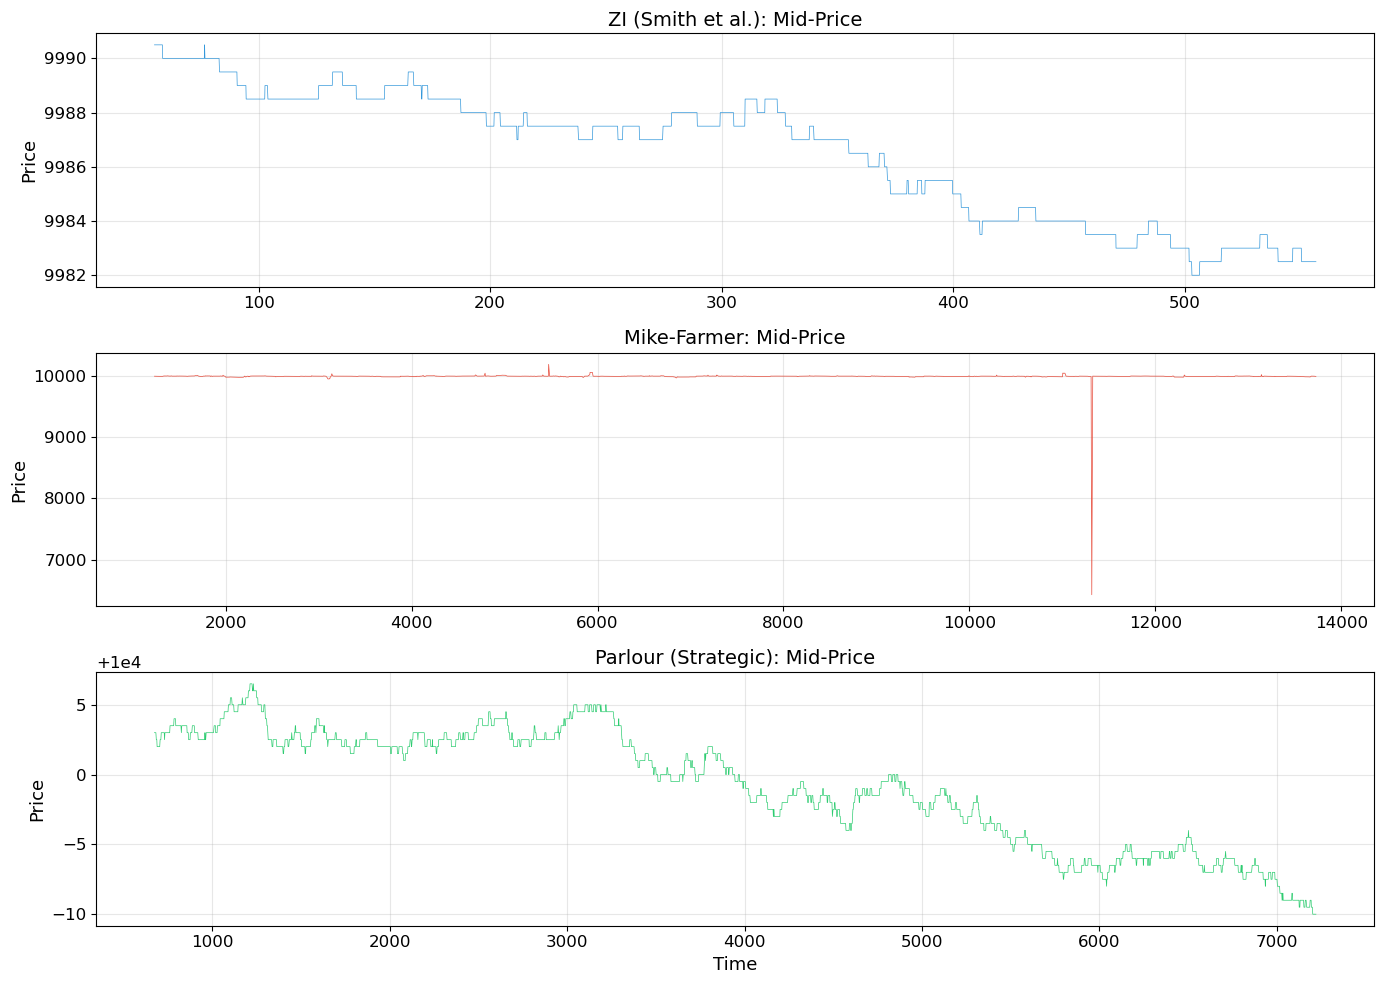

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
colors = {'ZI (Smith et al.)': '#3498db', 'Mike-Farmer': '#e74c3c', 'Parlour (Strategic)': '#2ecc71'}

for i, (name, r) in enumerate(results.items()):
    v = r['valid']
    step = max(1, len(v) // 3000)
    sub = v.iloc[::step]
    axes[i].plot(sub['time'].values, sub['mid_price'].values,
                 color=colors[name], linewidth=0.5)
    axes[i].set_title(f'{name}: Mid-Price')
    axes[i].set_ylabel('Price')

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

## 3. Return Distribution Comparison

Key question: Which model produces the heavy tails seen in real markets?

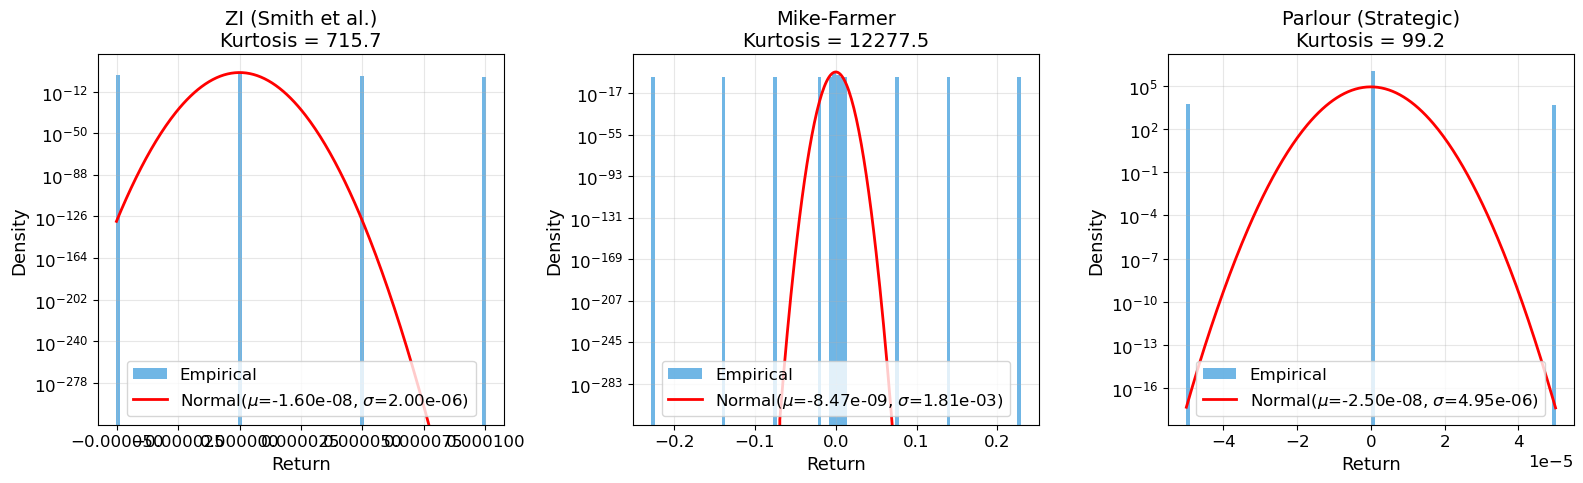

Kurtosis comparison (Gaussian = 0, heavy-tailed >> 0):
  ZI (Smith et al.)        : kurtosis =    715.7, Hill tail index = 14.43
  Mike-Farmer              : kurtosis =  12277.5, Hill tail index = 0.97
  Parlour (Strategic)      : kurtosis =     99.2, Hill tail index = 7327.36


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, (name, r) in enumerate(results.items()):
    ret = r['log_returns']
    if len(ret) > 100:
        plot_return_distribution(ret, n_bins=100, ax=axes[i])
        kurt = stats.kurtosis(ret)
        axes[i].set_title(f'{name}\nKurtosis = {kurt:.1f}')

plt.tight_layout()
plt.show()

print("Kurtosis comparison (Gaussian = 0, heavy-tailed >> 0):")
for name, r in results.items():
    ret = r['log_returns']
    if len(ret) > 100:
        kurt = stats.kurtosis(ret)
        tail = hill_estimator(ret)
        print(f"  {name:25s}: kurtosis = {kurt:8.1f}, Hill tail index = {tail:.2f}")

## 4. Volatility Clustering Comparison

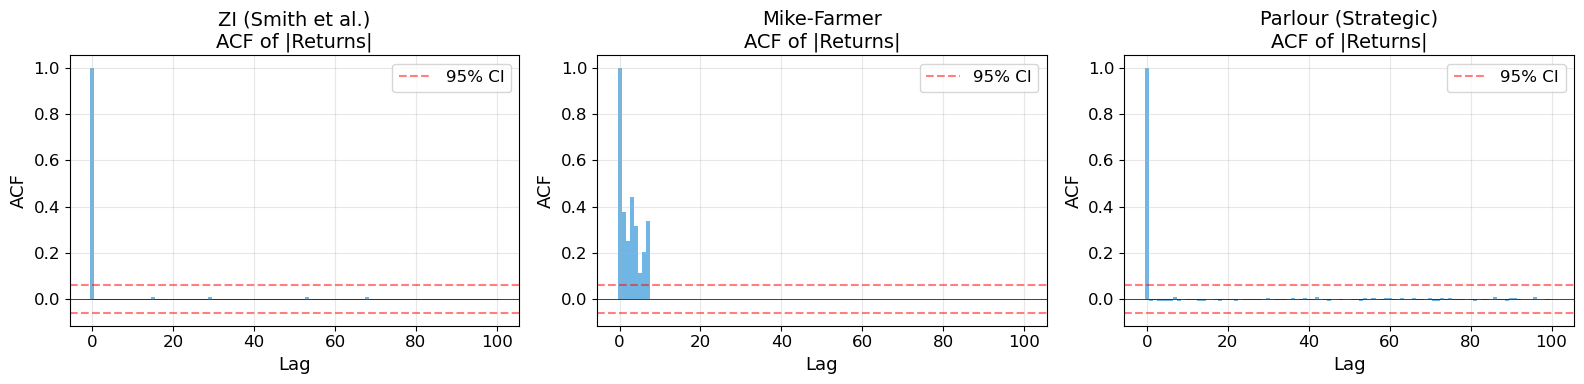

Volatility clustering (ACF of |returns| at lag 10):
  ZI (Smith et al.)        : ACF(10) = -0.0015, ACF(50) = -0.0015
  Mike-Farmer              : ACF(10) = 0.0000, ACF(50) = -0.0002
  Parlour (Strategic)      : ACF(10) = -0.0016, ACF(50) = 0.0005


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, (name, r) in enumerate(results.items()):
    ret = r['log_returns']
    if len(ret) > 200:
        acf_vol = compute_volatility_clustering(ret, max_lag=100)
        plot_acf(acf_vol, title=f'{name}\nACF of |Returns|', ax=axes[i])

plt.tight_layout()
plt.show()

print("Volatility clustering (ACF of |returns| at lag 10):")
for name, r in results.items():
    ret = r['log_returns']
    if len(ret) > 200:
        acf_vol = compute_volatility_clustering(ret, max_lag=50)
        print(f"  {name:25s}: ACF(10) = {acf_vol[10]:.4f}, ACF(50) = {acf_vol[min(50, len(acf_vol)-1)]:.4f}")

## 5. Hurst Exponent Comparison

In [6]:
print(f"{'Model':25s} {'H(returns)':>12} {'H(|returns|)':>14} {'Interpretation':>20}")
print("-" * 75)

for name, r in results.items():
    ret = r['log_returns']
    if len(ret) > 500:
        H_ret = compute_hurst_rs(ret)
        H_abs = compute_hurst_rs(np.abs(ret))
        interp = "Long memory" if H_abs > 0.6 else "Weak/no memory"
        print(f"{name:25s} {H_ret:>12.3f} {H_abs:>14.3f} {interp:>20}")

print()
print("Real markets: H(returns) ~ 0.5, H(|returns|) > 0.5")

Model                       H(returns)   H(|returns|)       Interpretation
---------------------------------------------------------------------------
ZI (Smith et al.)                0.495          0.528       Weak/no memory
Mike-Farmer                      0.507          0.647          Long memory
Parlour (Strategic)              0.494          0.524       Weak/no memory

Real markets: H(returns) ~ 0.5, H(|returns|) > 0.5


## 6. Spread Distribution

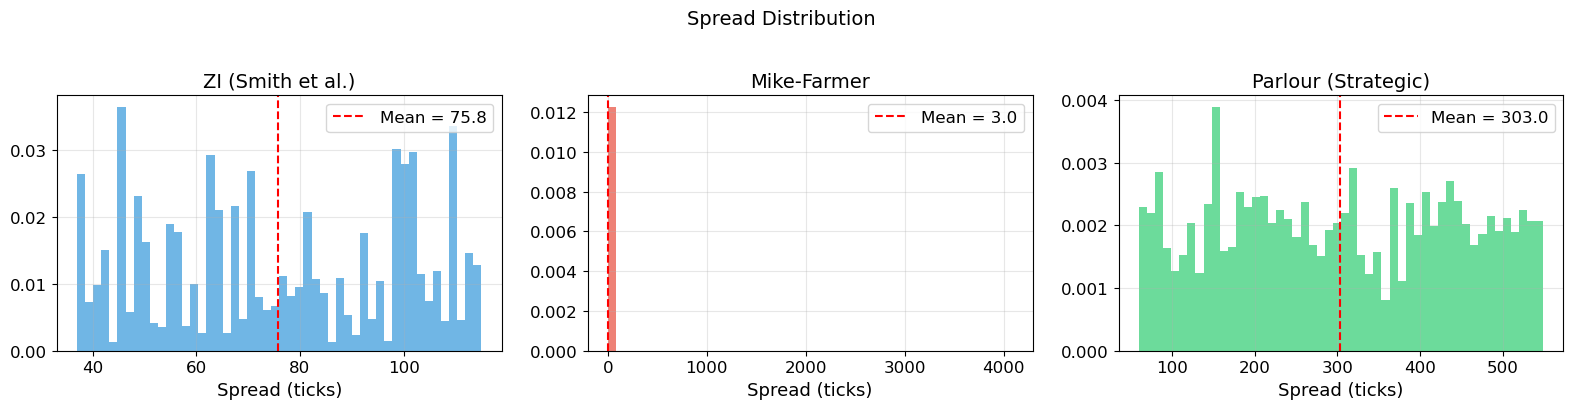

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, (name, r) in enumerate(results.items()):
    spreads = r['valid']['spread'].dropna().values
    axes[i].hist(spreads, bins=50, density=True, alpha=0.7, color=list(colors.values())[i])
    axes[i].axvline(x=np.mean(spreads), color='red', linestyle='--',
                    label=f'Mean = {np.mean(spreads):.1f}')
    axes[i].set_title(f'{name}')
    axes[i].set_xlabel('Spread (ticks)')
    axes[i].legend()

plt.suptitle('Spread Distribution', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 7. Model Comparison Scorecard

How well does each model reproduce the empirical stylized facts?

In [8]:
scorecard = pd.DataFrame({
    'Stylized Fact': [
        'Emergent spread',
        'Depth profile shape',
        'Heavy-tailed returns',
        'Volatility clustering',
        'Long memory in |returns|',
        'Bid-ask bounce (neg ACF lag-1)',
        'Power-law relative prices',
        'Long memory in order signs',
        'Concave price impact',
    ],
    'ZI (Smith et al.)': [
        'Yes', 'Partial', 'No', 'No', 'No', 'Yes', 'No (uniform)', 'No (independent)', 'Partial',
    ],
    'Mike-Farmer': [
        'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes (built-in)', 'Yes (built-in)', 'Yes',
    ],
    'Parlour (Strategic)': [
        'Yes', 'Partial', 'Partial', 'Weak', 'Weak', 'Yes', 'No', 'No', 'Partial',
    ],
})

# Style the DataFrame
def color_cell(val):
    if val == 'Yes' or 'Yes' in str(val):
        return 'background-color: #d4edda'
    elif val == 'No' or 'No' in str(val):
        return 'background-color: #f8d7da'
    else:
        return 'background-color: #fff3cd'

display(scorecard.style.map(color_cell, subset=['ZI (Smith et al.)', 'Mike-Farmer', 'Parlour (Strategic)']))

,Stylized Fact,ZI (Smith et al.),Mike-Farmer,Parlour (Strategic)
0,Emergent spread,Yes,Yes,Yes
1,Depth profile shape,Partial,Yes,Partial
2,Heavy-tailed returns,No,Yes,Partial
3,Volatility clustering,No,Yes,Weak
4,Long memory in |returns|,No,Yes,Weak
5,Bid-ask bounce (neg ACF lag-1),Yes,Yes,Yes
6,Power-law relative prices,No (uniform),Yes (built-in),No
7,Long memory in order signs,No (independent),Yes (built-in),No
8,Concave price impact,Partial,Yes,Partial


## 8. The Feedback Loop (Parlour Model)

The Parlour model's key insight: traders **condition** on the book state. Let's visualize how the probability of submitting a market order changes with spread and depth.

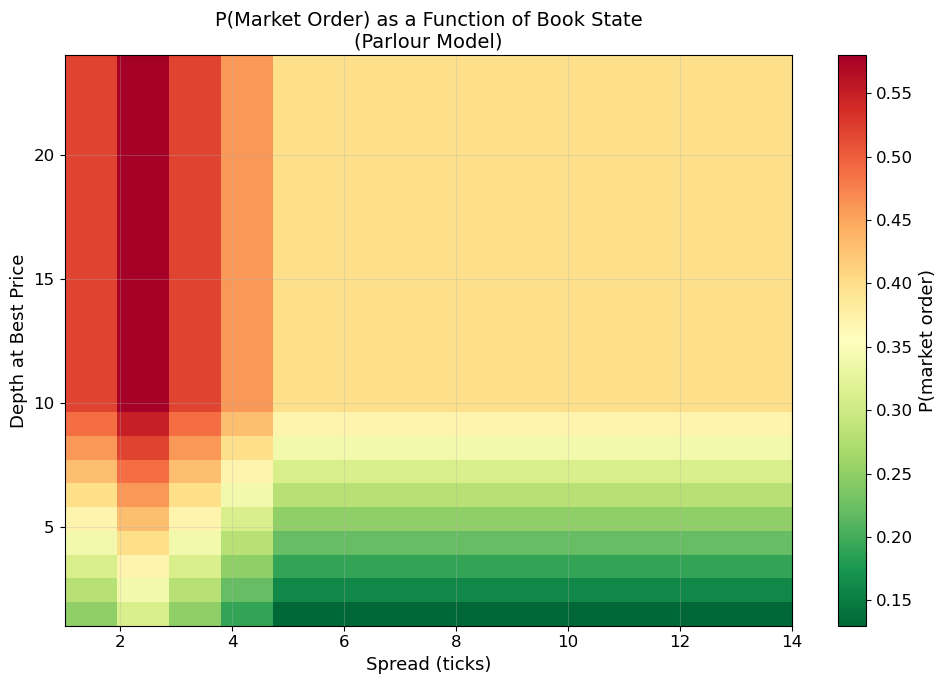

Narrow spread + deep queue → high P(market order)
Wide spread + shallow queue → low P(market order) → traders prefer limit orders

This feedback loop is the core mechanism of the Parlour (1998) model.


In [9]:
from lob.models.strategic import ParlourModel
from lob.book import OrderBook
from lob.order import Side, limit_order

pm = ParlourModel()

spreads_range = range(1, 15)
depths_range = range(1, 25)

prob_grid = np.zeros((len(list(depths_range)), len(list(spreads_range))))

for i, depth in enumerate(depths_range):
    for j, spread in enumerate(spreads_range):
        reset_order_id_counter()
        book = OrderBook()
        mid = 10000
        half_s = max(1, spread // 2)
        for _ in range(depth):
            book.add_order(limit_order(mid - half_s, 1, 0.0, Side.BID))
            book.add_order(limit_order(mid + half_s + (1 if spread % 2 else 0), 1, 0.0, Side.ASK))
        prob_grid[i, j] = pm._prob_market_order(book)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(prob_grid, aspect='auto', origin='lower', cmap='RdYlGn_r',
               extent=[1, 14, 1, 24])
ax.set_xlabel('Spread (ticks)')
ax.set_ylabel('Depth at Best Price')
ax.set_title('P(Market Order) as a Function of Book State\n(Parlour Model)')
plt.colorbar(im, label='P(market order)')
plt.tight_layout()
plt.show()

print("Narrow spread + deep queue → high P(market order)")
print("Wide spread + shallow queue → low P(market order) → traders prefer limit orders")
print("\nThis feedback loop is the core mechanism of the Parlour (1998) model.")

## Summary

Key insights from the model comparison:

1. **ZI Model** (Smith et al.): Good null model. Captures mechanical effects but misses heavy tails and long memory. Shows that *a lot of structure is just mechanics*.

2. **Mike-Farmer Model**: Empirically calibrated with power-law prices and long-memory order signs. Reproduces most stylized facts simultaneously. The price is complexity: many parameters and reliance on Monte Carlo.

3. **Parlour Model**: Captures the *feedback loop* between book state and trader decisions. Provides economic intuition but doesn't reproduce the statistical stylized facts as well.

As the paper notes: *"There is no clear consensus on the best approach"* — each model illuminates different aspects of LOB dynamics.

**Next:** Notebook 06 explores the open questions from Section 6.